# Day 1 · Data Exploration, Cleaning & First KPIs

*Work log: a cleaned version of my working notebook. The polished analysis lives in [`../01`–`05`](../).*

**Goals:** load 2.26M loans, explore and clean the data, define a "bad" loan, compute bad rate by grade, and build the approval-rate trend.

**Key results:** portfolio bad rate **14.5%** (2014–2015, 36-month cohort); bad rate rises from **5.4% (A) to 42.0% (G)**; approval rate peaked at **15.1% in 2013** and fell to **5.0% in 2018**.

## 1. Setup

In [1]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

DATA = (Path.cwd().parents[1] / "Data").resolve()   # project_root/Data
con = duckdb.connect()

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)

## 2. Convert the raw CSVs to Parquet (one-time)
The CSVs are ~1.7 GB each. Parquet is columnar and compressed, so later queries take seconds.

In [2]:
for name in ["accepted", "rejected"]:
    parquet = DATA / f"{name}.parquet"
    if parquet.exists():
        print(f"{parquet.name} already exists, skipping")
        continue
    con.sql(f"""
    COPY (
        SELECT *
        FROM read_csv('{DATA}/{name}_2007_to_2018Q4.csv',
                      sample_size = -1,      -- scan the whole file before inferring column types
                      ignore_errors = true)  -- skip malformed summary rows at the end of the file
    ) TO '{parquet}' (FORMAT parquet)
    """)
    print(f"created {parquet.name}")

accepted.parquet already exists, skipping
rejected.parquet already exists, skipping


## 3. First look at the data

In [3]:
# Register the file as a table named `loans`
con.sql(f"""
CREATE OR REPLACE VIEW loans AS
SELECT *
FROM '{DATA}/accepted.parquet'
""")

con.sql("""
SELECT COUNT(*) AS n_loans
FROM loans
""").df()

,n_loans
0,2260701


In [4]:
# Preview the key columns
con.sql("""
SELECT loan_amnt, term, int_rate, grade, loan_status
FROM loans
LIMIT 5
""").df()

,loan_amnt,term,int_rate,grade,loan_status
0,3600.0,36 months,13.99,C,Fully Paid
1,24700.0,36 months,11.99,C,Fully Paid
2,20000.0,60 months,10.78,B,Fully Paid
3,35000.0,60 months,14.85,C,Current
4,10400.0,60 months,22.45,F,Fully Paid


In [5]:
# `term` is stored as text, not a number
con.sql("""
SELECT DISTINCT term
FROM loans
""").df()

,term
0,36 months
1,60 months
2,NaN


In [6]:
# Loan status distribution: the basis for the good / bad definition
con.sql("""
SELECT loan_status,
       COUNT(*) AS n_loans
FROM loans
GROUP BY loan_status
ORDER BY n_loans DESC
""").df()

,loan_status,n_loans
0,Fully Paid,1076751
1,Current,878317
2,Charged Off,268559
3,Late (31-120 days),21467
4,In Grace Period,8436
5,Late (16-30 days),4349
6,Does not meet the credit policy. Status:Fully ...,1988
7,Does not meet the credit policy. Status:Charge...,761
8,Default,40
9,NaN,33


Planned grouping:
* **Good:** Fully Paid
* **Bad:** Charged Off, Default, Late (31–120 days)
* **Indeterminate:** Current, In Grace Period, Late (16–30 days). The outcome isn't known yet, so these are excluded rather than counted as good.

## 4. Data cleaning
### 4.1 Rows with a missing status

In [7]:
# These rows are file footer lines, not loans: `id` holds summary text ("Total amount funded...") and every other column is empty -> drop them
con.sql("""
SELECT *
FROM loans
WHERE loan_status IS NULL
LIMIT 5
""").df()

,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,pymnt_plan,url,desc,purpose,title,zip_code,addr_state,dti,delinq_2yrs,earliest_cr_line,fico_range_low,fico_range_high,inq_last_6mths,mths_since_last_delinq,mths_since_last_record,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,out_prncp,out_prncp_inv,total_pymnt,total_pymnt_inv,total_rec_prncp,total_rec_int,total_rec_late_fee,recoveries,collection_recovery_fee,last_pymnt_d,last_pymnt_amnt,next_pymnt_d,last_credit_pull_d,last_fico_range_high,last_fico_range_low,collections_12_mths_ex_med,mths_since_last_major_derog,policy_code,application_type,annual_inc_joint,dti_joint,verification_status_joint,acc_now_delinq,tot_coll_amt,tot_cur_bal,open_acc_6m,open_act_il,open_il_12m,open_il_24m,mths_since_rcnt_il,total_bal_il,il_util,open_rv_12m,open_rv_24m,max_bal_bc,all_util,total_rev_hi_lim,inq_fi,total_cu_tl,inq_last_12m,acc_open_past_24mths,avg_cur_bal,bc_open_to_buy,bc_util,chargeoff_within_12_mths,delinq_amnt,mo_sin_old_il_acct,mo_sin_old_rev_tl_op,mo_sin_rcnt_rev_tl_op,mo_sin_rcnt_tl,mort_acc,mths_since_recent_bc,mths_since_recent_bc_dlq,mths_since_recent_inq,mths_since_recent_revol_delinq,num_accts_ever_120_pd,num_actv_bc_tl,num_actv_rev_tl,num_bc_sats,num_bc_tl,num_il_tl,num_op_rev_tl,num_rev_accts,num_rev_tl_bal_gt_0,num_sats,num_tl_120dpd_2m,num_tl_30dpd,num_tl_90g_dpd_24m,num_tl_op_past_12m,pct_tl_nvr_dlq,percent_bc_gt_75,pub_rec_bankruptcies,tax_liens,tot_hi_cred_lim,total_bal_ex_mort,total_bc_limit,total_il_high_credit_limit,revol_bal_joint,sec_app_fico_range_low,sec_app_fico_range_high,sec_app_earliest_cr_line,sec_app_inq_last_6mths,sec_app_mort_acc,sec_app_open_acc,sec_app_revol_util,sec_app_open_act_il,sec_app_num_rev_accts,sec_app_chargeoff_within_12_mths,sec_app_collections_12_mths_ex_med,sec_app_mths_since_last_major_derog,hardship_flag,hardship_type,hardship_reason,hardship_status,deferral_term,hardship_amount,hardship_start_date,hardship_end_date,payment_plan_start_date,hardship_length,hardship_dpd,hardship_loan_status,orig_projected_additional_accrued_interest,hardship_payoff_balance_amount,hardship_last_payment_amount,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term
0,Total amount funded in policy code 1: 6417608175,None,NaN,NaN,NaN,None,NaN,NaN,None,None,None,None,None,NaN,None,None,None,None,None,None,None,None,None,None,NaN,NaN,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,NaN,None,None,NaN,NaN,NaN,NaN,NaN,None,NaN,NaN,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,None,None,None,NaN,NaN,None,None,None,NaN,NaN,None,NaN,NaN,NaN,None,None,None,None,None,NaN,NaN,NaN
1,Total amount funded in policy code 2: 1944088810,None,NaN,NaN,NaN,None,NaN,NaN,None,None,None,None,None,NaN,None,None,None,None,None,None,None,None,None,None,NaN,NaN,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,NaN,None,None,NaN,NaN,NaN,NaN,NaN,None,NaN,NaN,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,None,None,None,NaN,NaN,None,None,None,NaN,NaN,None,NaN,NaN,NaN,None,None,None,None,None,NaN,NaN,NaN
2,Total amount funded in policy code 1: 1741781700,None,NaN,NaN,NaN,None,NaN,NaN,None,None,None,None,None,NaN,None,None,None,None,None,None,None,None,None,None,NaN,NaN,None,NaN,NaN,NaN,NaN,NaN,NaN,Na

In [8]:
con.sql("""
CREATE OR REPLACE VIEW loans_clean AS
SELECT *
FROM loans
WHERE loan_status IS NOT NULL
""")

# Sanity check: 2,260,701 - 33 = 2,260,668
con.sql("""
SELECT COUNT(*) AS n_clean_loans
FROM loans_clean
""").df()

,n_clean_loans
0,2260668


### 4.2 Issue date stored as text
`'Apr-2015'` sorts before `'Dec-2014'` alphabetically, so the column must be parsed into a real date.

In [9]:
con.sql("""
SELECT DISTINCT issue_d
FROM loans_clean
LIMIT 10
""").df()

,issue_d
0,Feb-2015
1,Mar-2015
2,Jan-2015
3,Mar-2018
4,Feb-2018
5,Jan-2018
6,Nov-2011
7,Oct-2011
8,Sep-2011
9,Aug-2011


In [10]:
# Rebuild loans_clean with a parsed date column (no day in the source, so it defaults to the 1st)
con.sql("""
CREATE OR REPLACE VIEW loans_clean AS
SELECT *,
       strptime(issue_d, '%b-%Y') AS issue_date
FROM loans
WHERE loan_status IS NOT NULL
""")

con.sql("""
SELECT MIN(issue_date) AS earliest_issue_date,
       MAX(issue_date) AS last_issue_date
FROM loans_clean
""").df()

,earliest_issue_date,last_issue_date
0,2007-06-01,2018-12-01


### 4.3 Hidden leading space in `term`
Filtering on `term = '36 months'` returned 0 rows. `'36 months'` has 9 characters, but the stored values have 10.

In [11]:
con.sql("""
SELECT DISTINCT term,
       LENGTH(term) AS term_length
FROM loans_clean
""").df()

,term,term_length
0,36 months,10
1,60 months,10


The values are `' 36 months'` with a leading space, so I use `TRIM(term)`.

## 5. Analysis cohort
The data ends in Dec-2018. 36-month loans issued in 2014–2015 have all matured, so their outcomes are final.

In [12]:
con.sql("""
CREATE OR REPLACE VIEW cohort AS
SELECT *
FROM loans_clean
WHERE issue_date BETWEEN '2014-01-01' AND '2015-12-31'
  AND TRIM(term) = '36 months'
""")

# Sanity check: expect 445,743 loans
con.sql("""
SELECT COUNT(*) AS n_loans
FROM cohort
""").df()

,n_loans
0,445743


In [13]:
# Almost every loan in the cohort has a final outcome
con.sql("""
SELECT loan_status,
       COUNT(*) AS n_loans
FROM cohort
GROUP BY loan_status
ORDER BY n_loans DESC
""").df()

,loan_status,n_loans
0,Fully Paid,381149
1,Charged Off,64447
2,Current,72
3,Late (31-120 days),61
4,In Grace Period,9
5,Late (16-30 days),5


## 6. Target variable: `bad_flag`

In [14]:
# Check the mapping: 1 = bad, 0 = good, NULL = indeterminate
con.sql("""
SELECT loan_status,
       CASE WHEN loan_status IN ('Charged Off', 'Late (31-120 days)') THEN 1
                        WHEN loan_status = 'Fully Paid' THEN 0 END AS bad_flag,
       COUNT(*) AS n_loans
FROM cohort
GROUP BY loan_status, bad_flag
ORDER BY n_loans DESC
""").df()

,loan_status,bad_flag,n_loans
0,Fully Paid,0,381149
1,Charged Off,1,64447
2,Current,<NA>,72
3,Late (31-120 days),1,61
4,In Grace Period,<NA>,9
5,Late (16-30 days),<NA>,5


In [15]:
# bad_flag is 0/1, so its average is the bad rate; AVG() skips the NULL (indeterminate) loans
con.sql("""
SELECT ROUND(AVG(CASE WHEN loan_status IN ('Charged Off', 'Late (31-120 days)') THEN 1
                        WHEN loan_status = 'Fully Paid' THEN 0 END), 4) AS bad_rate
FROM cohort
""").df()

,bad_rate
0,0.1447


In [16]:
# Bad rate and average interest rate by grade
con.sql("""
SELECT grade,
       COUNT(*)                AS n_loans,
       ROUND(AVG(int_rate), 2) AS avg_int_rate,
       ROUND(AVG(CASE WHEN loan_status IN ('Charged Off', 'Late (31-120 days)') THEN 1
                        WHEN loan_status = 'Fully Paid' THEN 0 END), 4) AS bad_rate
FROM cohort
GROUP BY grade
ORDER BY grade
""").df()

,grade,n_loans,avg_int_rate,bad_rate
0,A,105465,7.09,0.0542
1,B,145243,10.45,0.1148
2,C,121499,13.54,0.1864
3,D,53250,16.79,0.2467
4,E,16516,19.62,0.3036
5,F,3343,23.92,0.3479
6,G,427,26.39,0.4198


**Finding:** grade rank-orders risk well. The bad rate climbs steadily from 5.4% (A) to 42.0% (G). Grade G has only 427 loans, so its rate is less stable.

## 7. Business volume by year

In [17]:
# funded_amnt = amount actually lent (loan_amnt is the amount requested)
con.sql("""
SELECT YEAR(issue_date)                      AS issue_year,
       COUNT(*)                              AS n_loans,
       ROUND(SUM(funded_amnt) / 1000000, 1)  AS amount_mm
FROM loans_clean
GROUP BY issue_year
ORDER BY issue_year
""").df()

,issue_year,n_loans,amount_mm
0,2007,603,4.8
1,2008,2393,20.0
2,2009,5281,51.8
3,2010,12537,126.4
4,2011,21721,257.4
5,2012,53367,717.9
6,2013,134814,1982.8
7,2014,235629,3503.8
8,2015,421095,6417.6
9,2016,434407,6400.5


2007 only covers June–December, so growth is measured from 2008. Volume roughly doubled every year until 2015 and then stalled in 2016.

## 8. Approval rate
### 8.1 Rejected applications

In [18]:
con.sql(f"""
CREATE OR REPLACE VIEW rejected AS
SELECT *
FROM '{DATA}/rejected.parquet'
""")

con.sql("""
SELECT COUNT(*) AS n_rejected
FROM rejected
""").df()

,n_rejected
0,27648741


In [19]:
# Only 9 application-time columns: a declined application never gets a term, rate, grade or status
con.sql("""
SELECT *
FROM rejected
LIMIT 5
""").df()

,Amount Requested,Application Date,Loan Title,Risk_Score,Debt-To-Income Ratio,Zip Code,State,Employment Length,Policy Code
0,1000.0,2007-05-26,Wedding Covered but No Honeymoon,693.0,10%,481xx,NM,4 years,0.0
1,1000.0,2007-05-26,Consolidating Debt,703.0,10%,010xx,MA,< 1 year,0.0
2,11000.0,2007-05-27,Want to consolidate my debt,715.0,10%,212xx,MD,1 year,0.0
3,6000.0,2007-05-27,waksman,698.0,38.64%,017xx,MA,< 1 year,0.0
4,1500.0,2007-05-27,mdrigo,509.0,9.43%,209xx,MD,< 1 year,0.0


### 8.2 Approval rate by year
Approval rate = approved ÷ (approved + rejected). The two yearly counts are built in CTEs and joined on year.

In [20]:
df = con.sql("""
WITH a AS (
    SELECT YEAR(issue_date) AS issue_year,
           COUNT(*)         AS n_accepted
    FROM loans_clean
    GROUP BY issue_year
),
r AS (
    SELECT YEAR("Application Date") AS issue_year,   -- column name contains a space, so it needs double quotes
           COUNT(*)                 AS n_rejected
    FROM rejected
    GROUP BY issue_year
)
SELECT a.issue_year,
       a.n_accepted,
       r.n_rejected,
       ROUND(a.n_accepted * 1.0 / (a.n_accepted + r.n_rejected), 4) AS approval_rate   -- * 1.0 avoids integer division
FROM a
LEFT JOIN r ON a.issue_year = r.issue_year
ORDER BY a.issue_year
""").df()
df

,issue_year,n_accepted,n_rejected,approval_rate
0,2007,603,5274,0.1026
1,2008,2393,25596,0.0855
2,2009,5281,56991,0.0848
3,2010,12537,112561,0.1002
4,2011,21721,217792,0.0907
5,2012,53367,337277,0.1366
6,2013,134814,760942,0.1505
7,2014,235629,1933700,0.1086
8,2015,421095,2859379,0.1284
9,2016,434407,4769874,0.0835


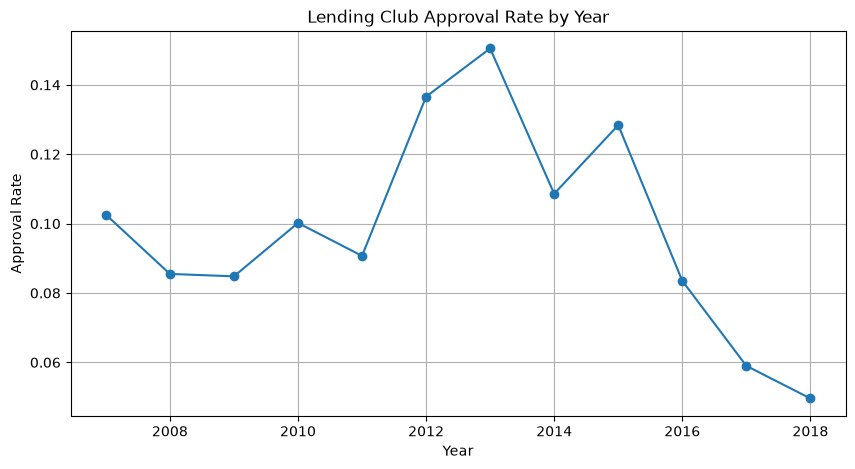

In [21]:
plt.figure(figsize=(10, 5))
plt.plot(df["issue_year"], df["approval_rate"], marker="o")
plt.title("Lending Club Approval Rate by Year")
plt.xlabel("Year")
plt.ylabel("Approval Rate")
plt.grid(True)
plt.show()

**Finding:** the approval rate peaked at 15.1% in 2013 and fell to 5.0% by 2018. Splitting the ratio into its two parts shows why: from 2015 to 2018, approvals grew 18%, but applications grew about 205%. The drop comes from the denominator (far more applicants), not from fewer approvals.